In [7]:
from pycaret.regression import setup, create_model, predict_model, get_config, compare_models, plot_model
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random

In [2]:
data = []
for _ in range(1000):
    x0 = random.randint(100, 200)
    x1 = random.randint(0, 50)
    noise = random.gauss(0, 10)
    y = 2 * x0 + 0.9 * x1 + noise
    data.append({
        'x0' : x0,
        'x1' : x1,
        'x2' : random.randint(0, 10),
        'y' : y
    })

df = pd.DataFrame(data)

<Axes: xlabel='x2', ylabel='y'>

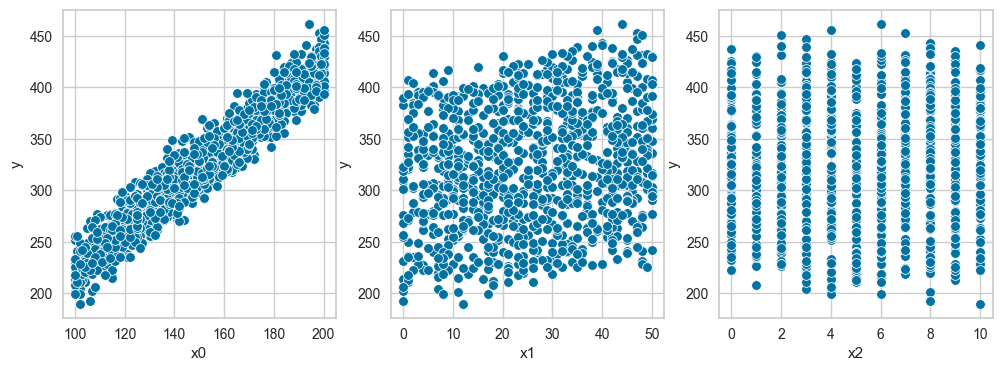

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.scatterplot(data=df, x='x0', y='y', ax=axes[0])
sns.scatterplot(data=df, x='x1', y='y', ax=axes[1])
sns.scatterplot(data=df, x='x2', y='y', ax=axes[2])

In [4]:
setup(data=df, target="y", session_id=123, n_jobs=1)

,Description,Value
0,Session id,123
1,Target,y
2,Target type,Regression
3,Original data shape,"(1000, 4)"
4,Transformed data shape,"(1000, 4)"
5,Transformed train set shape,"(700, 4)"
6,Transformed test set shape,"(300, 4)"
7,Numeric features,3
8,Preprocess,True
9,Imputation type,simple


In [5]:
best = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
lr,Linear Regression,7.5167,92.7652,9.5811,0.9736,0.0312,0.0241,0.0090
ridge,Ridge Regression,7.5167,92.7651,9.5811,0.9736,0.0312,0.0241,0.0080
en,Elastic Net,7.5211,92.7884,9.5827,0.9736,0.0312,0.0241,0.0090
lar,Least Angle Regression,7.5167,92.7652,9.5811,0.9736,0.0312,0.0241,0.0090
br,Bayesian Ridge,7.5169,92.7640,9.5810,0.9736,0.0312,0.0241,0.0090
lasso,Lasso Regression,7.5237,92.8540,9.5865,0.9735,0.0312,0.0241,0.0080
llar,Lasso Least Angle Regression,7.5237,92.8540,9.5865,0.9735,0.0312,0.0241,0.0080
huber,Huber Regressor,7.5146,92.8147,9.5841,0.9735,0.0312,0.0241,0.0130
gbr,Gradient Boosting Regressor,8.4063,112.4953,10.5458,0.9678,0.0345,0.0270,0.0590
lightgbm,Light Gradient Boosting Machine,8.5798,116.1361,10.7305,0.9666,0.0349,0.0275,0.0270


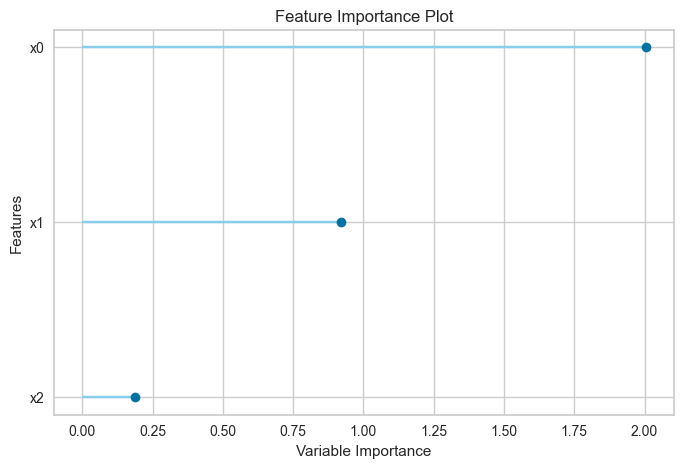

In [8]:
plot_model(best, plot='feature')